##Naive Bayes Classification

[Naive Bayes Classification](https://en.wikipedia.org/wiki/Naive_Bayes_classifier) is een methode waarmee je, op basis van een aantal bekende waarden, een nieuwe waarde (=categorie) kunt voorspellen.
Er zijn 2 manieren:<br>
- Multinomial Naive Bayes: als de oorzaak variabele bestaat uit (discrete) categorieen / aantallen<br>
- Gaussian Naive Bayes: als de oorzaak variabele bestaat uit (continue) getallen<br>

<p>
Dit klinkt nogal abstract, dus laten we enkele voorbeelden bekijken.<br>

https://medium.com/@christopherfielding/na%C3%AFve-bayes-classification-for-discrete-and-continuous-variables-cb1103155488

https://www.geeksforgeeks.org/multinomial-naive-bayes/
<p>
We gaan het ook zelf proberen. Eerst lezen we de benodigde libraries en functies in:


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Voorbeeld 1 VU studentendataset (Multinomial)

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df = df.loc[:, ["sex", "ls"]]
df.head() # We take a look at the first 5 rows

,sex,ls
0,FEMALE,PLEASED
1,MALE,MOSTLY SATISFIED
2,FEMALE,PLEASED
3,FEMALE,MIXED
4,FEMALE,MOSTLY SATISFIED


In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
rel_data_path = "/content/drive/MyDrive/vustudentanalytics.xlsx"

In [6]:
df = pd.read_excel(rel_data_path)
df = df.loc[:, ["sex", "ls"]]
df.head() # We take a look at the first 5 rows

,sex,ls
0,FEMALE,PLEASED
1,MALE,MOSTLY SATISFIED
2,FEMALE,PLEASED
3,FEMALE,MIXED
4,FEMALE,MOSTLY SATISFIED


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   sex     5000 non-null   object
 1   ls      4992 non-null   object
dtypes: object(2)
memory usage: 78.3+ KB


We verwijderen de NaN-waardes:

In [8]:
df_analyse = df.dropna()
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4992 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   sex     4992 non-null   object
 1   ls      4992 non-null   object
dtypes: object(2)
memory usage: 117.0+ KB


Voordat we de classificatie kunnen uitvoeren, moeten we eerst de x-waarden omzetten in discrete getallen:

In [9]:
one_hot = pd.get_dummies(df_analyse.loc[:, ["sex"]], dtype=int, prefix="sex")
one_hot

,sex_FEMALE,sex_MALE
0,1,0
1,0,1
2,1,0
3,1,0
4,1,0
...,...,...
4995,0,1
4996,1,0
4997,1,0
4998,0,1


En deze nieuwe tabel toevoegen aan de eerder geselecteerde data:

In [10]:
df_met_one_hot = pd.concat([df_analyse, one_hot], axis=1)

df_met_one_hot = df_met_one_hot.dropna()

df_met_one_hot

,sex,ls,sex_FEMALE,sex_MALE
0,FEMALE,PLEASED,1,0
1,MALE,MOSTLY SATISFIED,0,1
2,FEMALE,PLEASED,1,0
3,FEMALE,MIXED,1,0
4,FEMALE,MOSTLY SATISFIED,1,0
...,...,...,...,...
4995,MALE,MOSTLY SATISFIED,0,1
4996,FEMALE,MOSTLY SATISFIED,1,0
4997,FEMALE,MOSTLY SATISFIED,1,0
4998,MALE,MOSTLY SATISFIED,0,1


Nog even een plaatje:

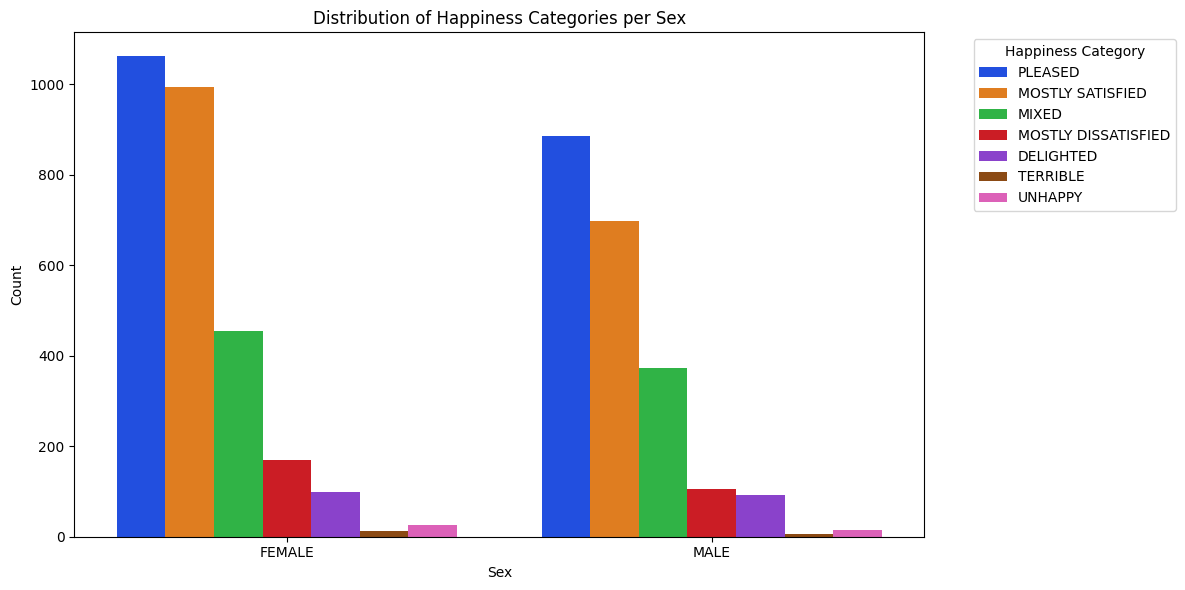

In [14]:
plt.figure(figsize=(12, 6))
sns.countplot(x='sex', hue='ls', data=df_met_one_hot, palette='bright')
plt.title('Distribution of Happiness Categories per Sex', color='black')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.legend(title='Happiness Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Voorspelling

In [15]:
X = df_met_one_hot.loc[:, ["sex_FEMALE", "sex_MALE"]]
y = df_met_one_hot['ls']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                random_state=1,
                                                test_size = 0.6)
model = MultinomialNB(alpha=0.01, fit_prior=True)
model.fit(X_train, y_train)
y_model = model.predict(X_test)
accuracy_score(y_test, y_model)

0.3885180240320427

Geslacht voorspelt in 38,8% van de gevallen de 'geluksstatus' van iemand: je kunt beter een muntje opgooien!

## Voorwaardelijke kansen

In [16]:
print('Conditional Log Probabilities (feature_log_prob):')
feature_names = X.columns
class_names = model.classes_
log_probs_df = pd.DataFrame(model.feature_log_prob_, columns=feature_names, index=class_names)
display(log_probs_df)

Conditional Log Probabilities (feature_log_prob):


,sex_FEMALE,sex_MALE
DELIGHTED,-0.625112,-0.766151
MIXED,-0.622799,-0.768822
MOSTLY DISSATISFIED,-0.495111,-0.940335
MOSTLY SATISFIED,-0.499961,-0.932812
PLEASED,-0.574091,-0.828318
TERRIBLE,-0.106248,-2.294633
UNHAPPY,-0.262902,-1.464547


In [17]:
regular_probs_df = np.exp(log_probs_df)
display(regular_probs_df)

,sex_FEMALE,sex_MALE
DELIGHTED,0.535201,0.464799
MIXED,0.536441,0.463559
MOSTLY DISSATISFIED,0.609503,0.390497
MOSTLY SATISFIED,0.606554,0.393446
PLEASED,0.563217,0.436783
TERRIBLE,0.899202,0.100798
UNHAPPY,0.768817,0.231183


De (voorwaardelijke) kans dat iemand met de status 'unhappy' een vrouw is, is 0,768: P(X = vrouw | Y = unhappy).

## Confusion matrix

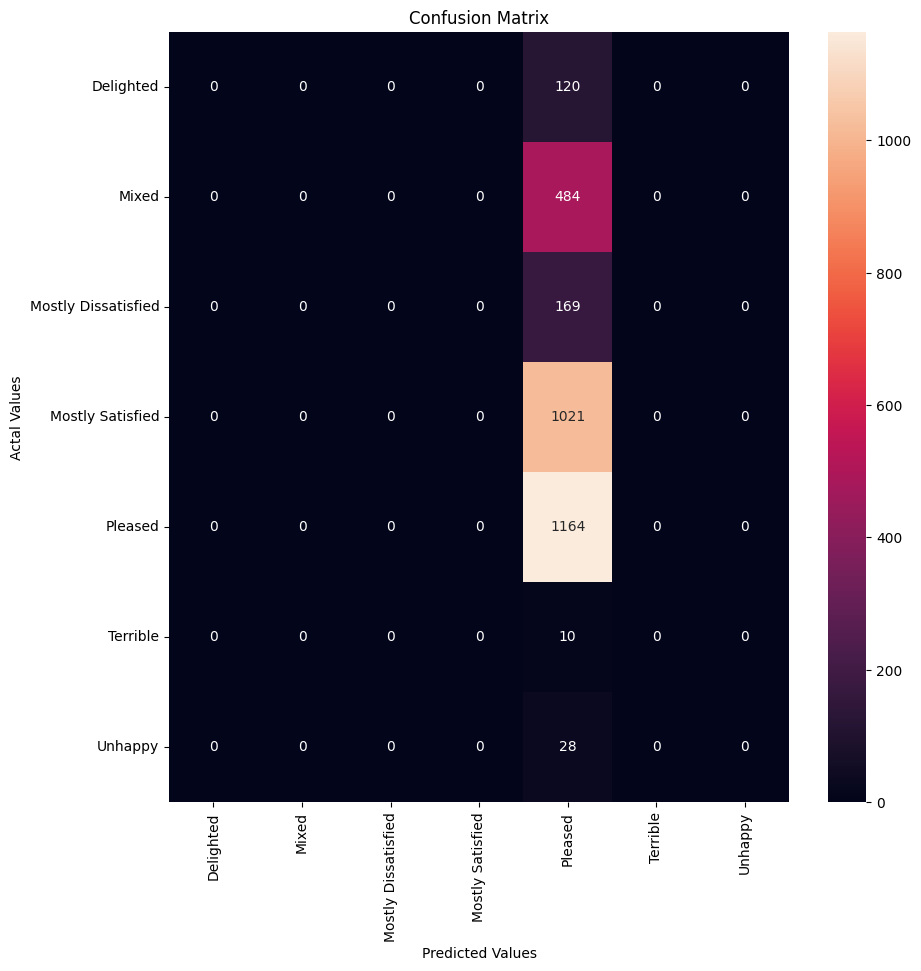

In [18]:
cm = confusion_matrix(y_test, y_model)
cm_df = pd.DataFrame(cm,
                     index = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'],
                     columns = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'])

#Plotting the confusion matrix
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [19]:
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != y_model).sum()))

Number of mislabeled points out of a total 2996 points : 1832


De confusion-matrix bevestigt dit beeld: maar 1.164 gevallen worden goed voorspeld (allemaal status 'pleased'), in 1.832 van de gevallen zit het voorspelmodel er naast!

# Voorbeeld 2 VU studentendataset (Multinomial)
Nog een voorbeeld:<br>
We gaan kijken of we het model kunnen 'leren' om op basis van het aantal vrienden de 'happiness' te voorspellen.

Eerst inlezen van een selectie (twee kolommen: nofriend en ls) van de data.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df = df.loc[:, ["nofriend", "ls"]]
df.head() # We take a look at the first 5 rows


,nofriend,ls
0,6,PLEASED
1,4,MOSTLY SATISFIED
2,20,PLEASED
3,0,MIXED
4,6,MOSTLY SATISFIED


In [ ]:
df.shape

(5000, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   nofriend  5000 non-null   int64 
 1   ls        4992 non-null   object
dtypes: int64(1), object(1)
memory usage: 78.2+ KB


We zien dat er 5.000 regels in de dataset zitten, maar in de ls-kolom ontbreken er waarden.<p>
Om Multinomial Naive Bayes Classification uit te kunnen voeren, mogen er geen NULL, NaN of negatieve waarden in de tabel zitten.<p>
Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse = df_analyse[df_analyse.nofriend >= 0]
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4951 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   nofriend  4951 non-null   int64 
 1   ls        4951 non-null   object
dtypes: int64(1), object(1)
memory usage: 116.0+ KB


We houden 4.951 regels over. Met deze selectie gaan we nu verder.<p>


Nog even een plaatje:

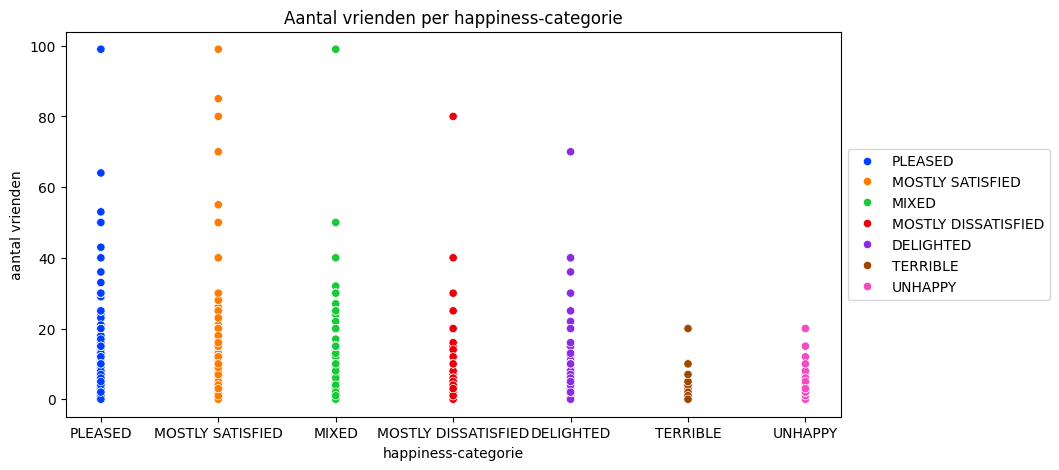

In [ ]:
sns.set_palette("bright")
plt.figure(figsize=(10,5))
ax = sns.scatterplot(x='ls',
                     y='nofriend',
                     data=df_analyse,
                     hue='ls')
plt.title('Aantal vrienden per happiness-categorie', color='black')
plt.xlabel('happiness-categorie')
plt.ylabel('aantal vrienden')
plt.legend(title='Happiness-categorie')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

## Voorspelling
We trainen en testen het model met behulp van het [Multinomial Naive Bayes-algoritme](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html):

In [ ]:
X = df_analyse.loc[:, ["nofriend"]]
y = df_analyse['ls']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                random_state=1,
                                                test_size = 0.6)
model = MultinomialNB()
model.fit(X_train, y_train)
y_model = model.predict(X_test)
accuracy_score(y_test, y_model)

0.3938067990575564

De accuratesse houdt niet over: maar 39,3% wordt goed 'voorspeld'.

In [ ]:
y_test

,ls
1280,PLEASED
3951,MOSTLY SATISFIED
3094,PLEASED
1789,PLEASED
1456,MOSTLY SATISFIED
...,...
2189,MOSTLY SATISFIED
2842,MIXED
4175,MOSTLY SATISFIED
4830,MIXED


## Confusion matrix
Tijd voor de confusion matrix:

In [ ]:
list = y_test.tolist()

d = list.count('DELIGHTED')
m = list.count('MIXED')
md = list.count('MOSTLY DISSATISFIED')
ms = list.count('MOSTLY SATISFIED')
p = list.count('PLEASED')
t = list.count('TERRIBLE')
u = list.count('UNHAPPY')

print(d)
print(m)
print(md)
print(ms)
print(p)
print(t)
print(u)

109
477
162
1019
1170
13
21


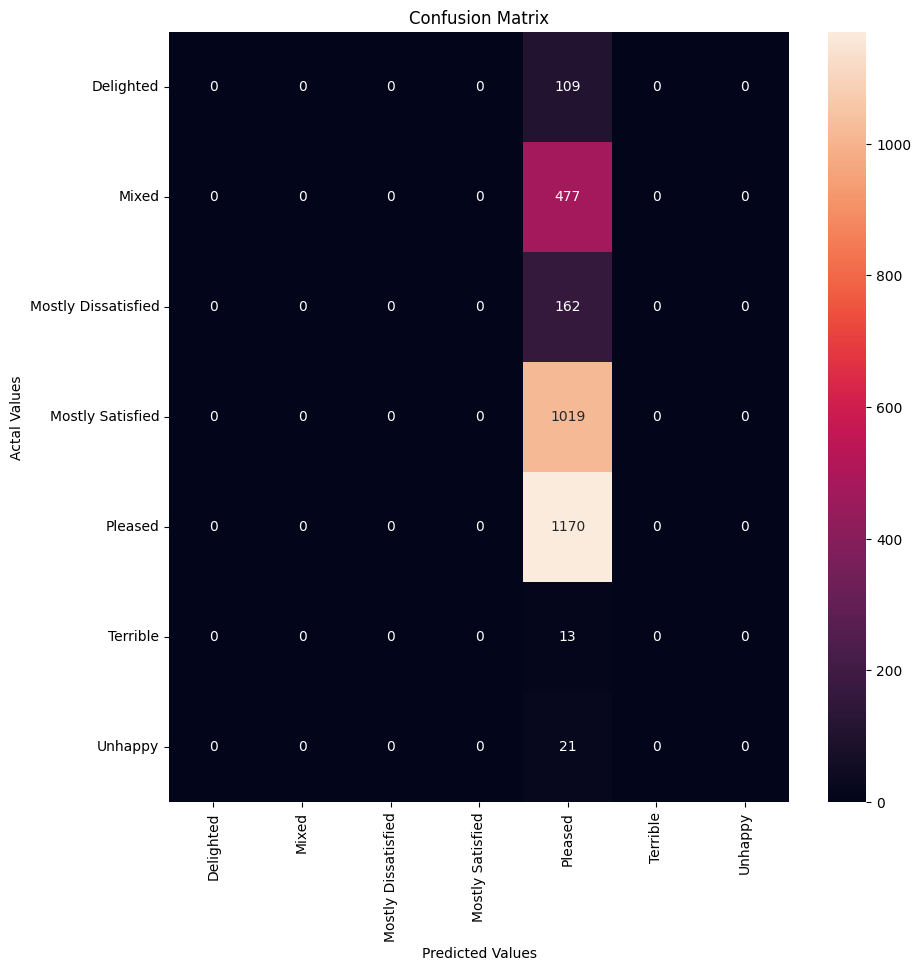

In [ ]:
cm = confusion_matrix(y_test, y_model)
cm_df = pd.DataFrame(cm,
                     index = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'],
                     columns = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'])

#Plotting the confusion matrix
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != y_model).sum()))

Number of mislabeled points out of a total 2971 points : 1801


Ook dit is een waardeloos voorspelmodel:<br>
van de 2.996 personen is er maar van 1.170 personen, op basis van het aantal vrienden, de 'happiness'-score juist voorspeld, en dat zijn ook nog eens alleen de 'pleased'-personen. Eigenlijk voorspelt dit model dat bijna alle personen de status 'pleased' hebben, ongeacht hun werkelijke (actual) status.
<p>
Aan jullie dus de opdracht:<br>
kijk of er bij jullie onderzoeksvragen, op basis van deze techniek, een goed (= accuraat) voorspelmodel is te maken.

# Voorbeeld 1 Pinguins (Gaussian)
Kun je, op basis van snavellengte en snaveldiepte, de soort pinguin voorspellen?
<p>
Via panda's wordt het bestand penguins_size.csv ingelezen.

De NaN's worden uit de dataframe gehaald:


In [ ]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
df = pd.read_csv("penguins_size.csv")
# =============================================================================
df = df.dropna()
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,334.000000,334.000000,334.000000,334.000000
mean,43.994311,17.160479,201.014970,4209.056886
std,5.460521,1.967909,14.022175,804.836129
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.575000,18.700000,213.000000,4793.750000
max,59.600000,21.500000,231.000000,6300.000000


In onderstaand scatterplot wordt de lengte en 'diepte' van de snavel tegen elkaar uitgezet.

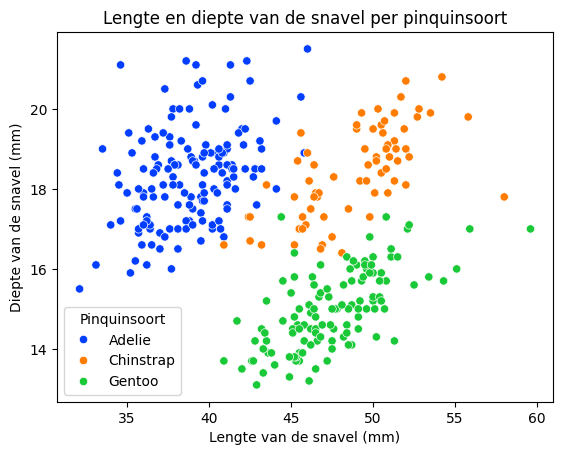

In [ ]:
sns.set_palette("bright")
ax = sns.scatterplot(x='culmen_length_mm',
                     y='culmen_depth_mm',
                     data=df,
                     hue='species')
plt.title('Lengte en diepte van de snavel per pinquinsoort', color='black')
plt.xlabel('Lengte van de snavel (mm)')
plt.ylabel('Diepte van de snavel (mm)')
plt.legend(title='Pinquinsoort')
plt.show()

In de scatterplot zien we duidelijk 3 groepen van verschillende soorten pinguins met een bepaalde combinatie van lengte en hoogte ('diepte'). Deze 2 variabelen zouden een goed voorspellingsmodel kunnen maken.

## Voorspelling
Laten we eens kijken of we een voorspelling kunnen maken.
<p>
Dat doen we door eerst de data te verdelen in een trainings-set (40%) en een test-set (60%). Met de trainings-set 'train' je het model = laat je het model berekenen welke pinguin, op basis van de grootste 'achteraf' kans, bij welke snavellengte- en diepte hoort.
<p>
Met de test-set voorspel je vervolgens op basis van de berekende kansen welke pinguin bij welke snavellengte- en diepte hoort.   

In [ ]:
X = df.loc[:, ["culmen_length_mm", "culmen_depth_mm"]]
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                random_state=1,
                                                test_size = 0.6)


In [ ]:
X_test

,culmen_length_mm,culmen_depth_mm
65,41.6,18.0
277,45.5,15.0
186,49.7,18.6
198,50.1,17.9
294,46.4,15.0
...,...,...
90,35.7,18.0
187,47.5,16.8
229,46.8,15.4
120,36.2,17.2


We trainen en testen het model met behulp van het [Gaussian Naive Bayes-algoritme](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html):

In [ ]:
model = GaussianNB()
model.fit(X_train, y_train)
y_model = model.predict(X_test)
accuracy_score(y_test, y_model)


0.9353233830845771

Een accuratesse van 93,5%, dat lijkt prima.

In [ ]:
list = y_test.tolist()

adelie = list.count('Adelie')
chinstrap = list.count('Chinstrap')
gentoo = list.count('Gentoo')

print(adelie)
print(chinstrap)
print(gentoo)


88
43
70


## Confusion matrix
We maken ook de '[confusion matrix](https://en.wikipedia.org/wiki/Confusion_matrix)':

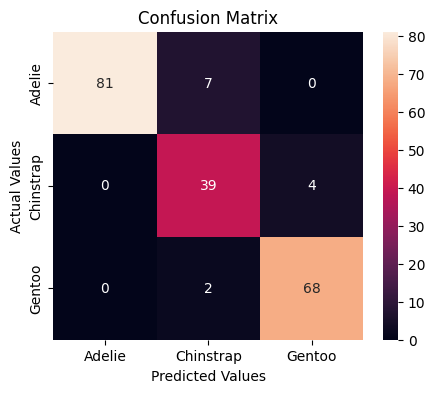

In [ ]:
cm = confusion_matrix(y_test, y_model)
cm_df = pd.DataFrame(cm,
                     index = ['Adelie','Chinstrap','Gentoo'],
                     columns = ['Adelie','Chinstrap','Gentoo'])

#Plotting the confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != y_model).sum()))

Number of mislabeled points out of a total 201 points : 13


Dus: van de 201 pinguins uit de test-set zijn er 188 goed voorspeld (de 'True Positives'), en 13 niet. <br>
Even de accuratesse controleren: 188/201 = 93,5%.
<p>
Als we nog iets beter kijken, zien we dat er:<br>
- 7 Adelie-pinguins ten onrechte als Chinstrap zijn gecategoriseerd<br>
- 4 Chinstraps ten onrechte als Gentoo en<br>
- 2 Gentoo's ten onrechte als Chinstrap.
<p>
Voor meer over 'confusion matrices':<br>
blog (https://www.analyticsvidhya.com/blog/2021/06/confusion-matrix-for-multi-class-classification) over confusion matrices.

#Voorbeeld 2 Schapen (Gaussian)
https://lifesciences.datastations.nl/dataset.xhtml?persistentId=doi:10.17026/dans-zp6-fmna

In [ ]:
df=pd.read_csv('S1.csv')
df = df.drop('pressure', axis=1)
df = df.dropna()
df

,label,animal_ID,segment_ID,timestamp_ms,ax,ay,az,axhg,ayhg,azhg,cx,cy,cz,gx,gy,gz,temp
0,walking,S1,1,1,-2.731780,-6.68701,-6.57208,2.13233,-5.375880,17.86960,1.5525,-0.4755,0.5415,2.012200,-51.3415,-32.6220,27.38
2,walking,S1,1,11,-2.827550,-6.96713,-6.54814,3.09339,-3.633980,17.02860,1.5405,-0.4785,0.5655,-1.890240,-42.5610,-35.0000,27.39
4,walking,S1,1,21,-2.892200,-7.30710,-6.37815,1.17128,-3.453780,16.54810,1.5405,-0.4785,0.5655,-2.987800,-33.0488,-38.3537,27.36
6,walking,S1,1,31,-2.894590,-7.53455,-6.09324,3.15345,-6.156740,18.77050,1.5240,-0.4950,0.5700,-0.060976,-25.4268,-40.7317,27.36
8,walking,S1,1,41,-2.863470,-7.44118,-6.00226,2.91319,-5.976540,17.50920,1.5450,-0.4770,0.5670,3.475610,-21.1585,-42.3171,27.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387986,trotting,S1,679,11939931,4.477160,-3.56736,-13.49370,9.25012,0.510559,8.82966,1.5315,-0.5205,0.6345,-127.561000,135.5490,79.3902,29.29
2387988,trotting,S1,679,11939941,3.627220,-4.07493,-14.82010,7.77851,1.411540,4.89536,1.5120,-0.5310,0.6270,-133.110000,145.0000,82.8049,29.28
2387990,trotting,S1,679,11939951,2.238580,-5.09486,-15.46180,8.61943,-0.720789,5.25575,1.5060,-0.5460,0.6300,-140.427000,132.5610,80.4878,29.25
2387992,trotting,S1,679,11939961,0.854730,-6.80193,-15.32290,5.43595,-3.694040,6.24684,1.5150,-0.5520,0.6300,-133.476000,92.9268,73.9024,29.25


In [ ]:
df.describe().apply(lambda s: s.apply('{0:.5f}'.format))

,segment_ID,timestamp_ms,ax,ay,az,axhg,ayhg,azhg,cx,cy,cz,gx,gy,gz,temp
count,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000,1193997.00000
mean,332.03460,5970062.66222,1.27907,-0.18000,-9.34915,6.03585,3.66520,14.64660,1.50683,-0.56050,0.54602,-0.27453,0.19020,-0.37248,29.71139
std,119.11027,3446771.50204,2.25157,5.02196,4.57936,2.60889,5.34178,5.02196,0.12181,0.16069,0.07379,92.18058,45.26158,36.49518,2.07529
min,1.00000,1.00000,-78.45320,-78.45320,-78.45320,-108.05800,-138.84200,-104.30400,1.20300,-0.92850,-0.09450,-1197.74000,-1659.63000,-996.52400,26.08000
25%,254.00000,2985096.00000,0.49081,-2.90656,-9.94312,4.80526,0.78085,13.09430,1.39050,-0.68400,0.51900,-13.84150,-9.39024,-10.00000,28.17000
50%,358.00000,5970071.00000,1.51792,1.13246,-9.40442,6.12670,4.68513,14.83620,1.51200,-0.57150,0.55650,-0.67073,-0.06098,0.06098,30.07000
75%,383.00000,8955071.00000,2.24816,2.85628,-8.44914,7.38808,6.87753,16.33790,1.61400,-0.44700,0.59550,12.19510,8.90244,9.63415,31.13000
max,679.00000,11939971.00000,78.45080,78.45080,64.51420,109.04900,708.98600,148.72300,1.90200,-0.14850,0.69300,1519.33000,1536.22000,1086.77000,34.59000


Plaatje met ' Wat doet het schaap?':

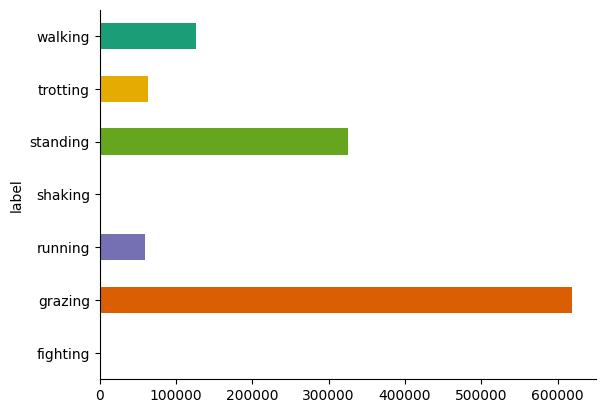

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
df.groupby('label').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

## Voorspelling
Kunnen we de status van het schaap voorspellen op basis van zijn/haar temperatuur?

In [ ]:
X = df.loc[:, ["temp"]]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                random_state=1,
                                                test_size = 0.6)

In [ ]:
model = GaussianNB()
model.fit(X_train, y_train)
y_model = model.predict(X_test)
accuracy_score(y_test, y_model)

0.5183982668875864

De voorspelling is net iets beter (51,8%) dan een muntje opgooien. Temperatuur alleen is dus geen goede voorspeller van wat een schaap doet.

## Confusion matrix

In [ ]:
list = y_test.tolist()

f = list.count('fighting')
g = list.count('grazing')
r = list.count('running')
s = list.count('shaking')
st = list.count('standing')
t = list.count('trotting')
w = list.count('walking')

print(f)
print(g)
print(r)
print(s)
print(st)
print(t)
print(w)

693
371380
35588
392
195395
37658
75293


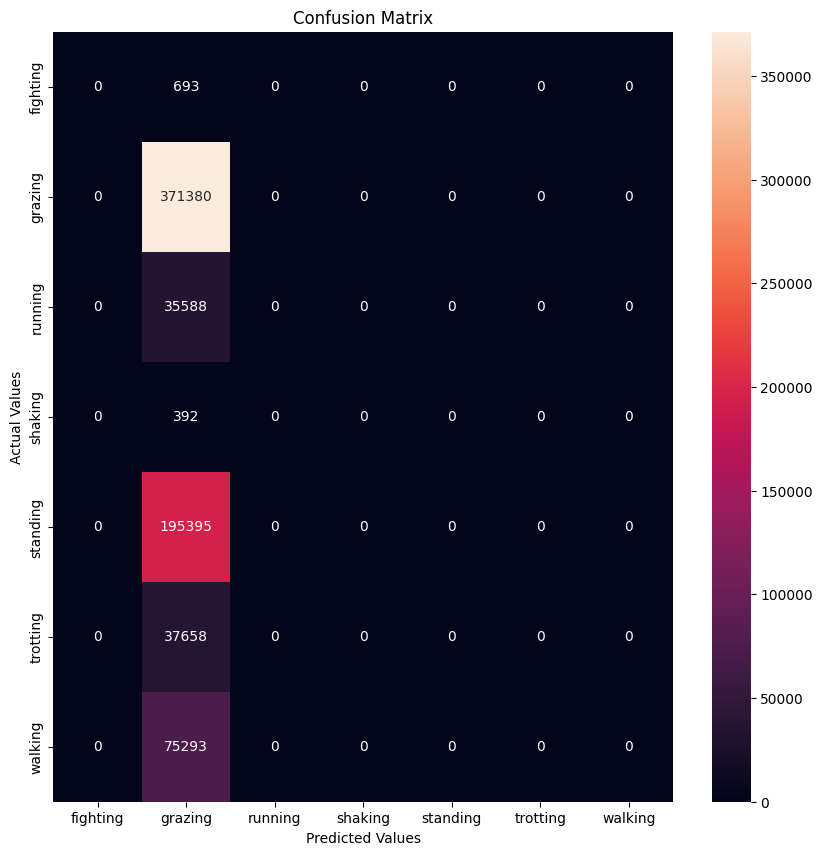

In [ ]:
cm = confusion_matrix(y_test, y_model)
cm_df = pd.DataFrame(cm,
                     index = ['fighting','grazing','running','shaking','standing','trotting','walking'],
                     columns = ['fighting','grazing','running','shaking','standing','trotting','walking'])

#Plotting the confusion matrix
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

Ook hier: waardeloos voorspelmodel, ieder schaap, ongeacht zijn/haar temperatuur, is aan het grazen (= meest voorkomende status).

Wat we wel hebben, is nu een (weliswaar waardeloos) voorspelmodel, waarmee we op basis van iedere temperatuur een voorspelling kunnen maken van het gedrag van het schaap:

In [ ]:
X_test == 100
y_model = model.predict(X_test)
y_model

array(['grazing', 'grazing', 'grazing', ..., 'grazing', 'grazing',
       'grazing'], dtype='<U8')

Opppasen dus (zie uitkomst hierboven): je kunt met AI de grootste onzin voorspellen!